# Viscosity model comparison - XGBoost vs others

Can batch process features predict Press 1 **Viscosity**, which model does it best, and which X matter?

- Data: `../Digester_Analysis/data/batch_master.csv` (1 row = 1 batch). **No PI access.**
- Validation: `TimeSeriesSplit` - always train on the past, test on the future. Gate = R² ≥ 0.30.
- **To add / remove a tag: edit `FEATURES` in `config.py`, then Restart & Run All.**
- Charts are saved to `output/` (git-ignored).

In [37]:
import importlib
import pandas as pd

import config, data, models, explain, plots
for mod in (config, data, models, explain, plots):   # pick up edits without restarting the kernel
    importlib.reload(mod)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Feature coverage
Every feature from `config.FEATURES`: does the column exist, and how many batches per digester have it?
Need a column name? Run `data.list_columns("alkali")`.

In [38]:
data.coverage()

rows: 3105 batches -> 642 with a Viscosity result after filters


,feature,label,status,pct_nan,n_D1,n_D2,n_D3,n_D4
0,alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,ok,0.0,158,182,198,104
1,pfactor_actual_last_prehydrolysis,P-factor,ok,0.0,158,182,198,104
2,heat_and_cook_minutes,H&C minutes,ok,0.0,158,182,198,104
3,white_liquor_per_ton_chip,WL / t chip,ok,0.0,158,182,198,104
4,liquor_to_wood_ratio,L:W,ok,0.0,158,182,198,104
5,LP_pressure_mean_heat_and_cook,LP pressure,ok,0.0,158,182,198,104
6,pfactor_rate,P-factor rate,ok,0.0,158,182,198,104
7,pfactor_temp_max_prehydrolysis,P-temp max,ok,0.0,158,182,198,104
8,prehydrolysis_minutes,Prehyd minutes,ok,0.0,158,182,198,104
9,pfactor_overshoot,P-factor overshoot,ok,0.0,158,182,198,104


In [39]:
df, feats = data.build_xy()
feats

rows: 3105 batches -> 642 with a Viscosity result after filters
rows with all 15 features: 484  (2026-05-09 .. 2026-10-15)


['alkali_accumulator1_conc_mean_hot_liquor_filling',
 'pfactor_actual_last_prehydrolysis',
 'heat_and_cook_minutes',
 'white_liquor_per_ton_chip',
 'liquor_to_wood_ratio',
 'LP_pressure_mean_heat_and_cook',
 'pfactor_rate',
 'pfactor_temp_max_prehydrolysis',
 'prehydrolysis_minutes',
 'pfactor_overshoot',
 'minutes_above_168',
 'ptemp_overshoot',
 'is_D2',
 'is_D3',
 'is_D4']

## 2. Model leaderboard
Same rows, same time split for every model. `baseline` = predict the train mean (it can be < 0 when the mean drifts).

  scoring baseline       pooled
  scoring ridge          pooled
  scoring ridge          pooled + DigID
  scoring random_forest  pooled
  scoring random_forest  pooled + DigID
  scoring sklearn_gbm    pooled
  scoring sklearn_gbm    pooled + DigID
  scoring xgboost        pooled
  scoring xgboost        pooled + DigID
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\leaderboard.png


,model,type,features,R2,MAE,n_test,pass_gate
0,random_forest,trees (bagging),pooled + DigID,-0.175,37.1,363,False
1,random_forest,trees (bagging),pooled,-0.178,37.2,363,False
2,ridge,linear,pooled + DigID,-0.181,36.6,363,False
3,ridge,linear,pooled,-0.188,36.6,363,False
4,sklearn_gbm,trees (boosting),pooled + DigID,-0.212,37.4,363,False
5,xgboost,trees (boosting),pooled + DigID,-0.217,37.4,363,False
6,sklearn_gbm,trees (boosting),pooled,-0.224,37.5,363,False
7,xgboost,trees (boosting),pooled,-0.229,37.6,363,False
8,baseline,mean of train,pooled,-0.360,42.3,363,False


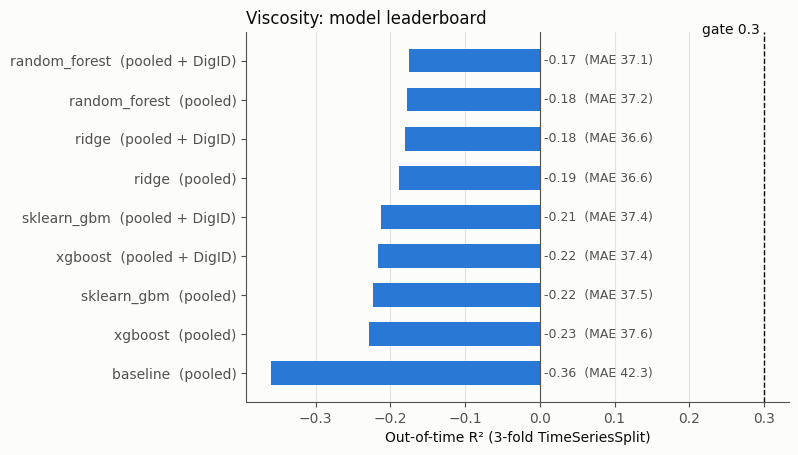

In [40]:
board = models.leaderboard(df, feats)
plots.leaderboard_bar(board)
board
#MAE (Mean Absolute Error) = ทายผิดเฉลี่ยกี่หน่วย
#R² (R-squared) = model อธิบายการแกว่งของ Viscosity ได้กี่เปอร์เซ็นต์

### Per-digester models (for comparison)
Each digester alone, process features only. Small n -> unstable; pooled is expected to win.

In [41]:
pd.concat([models.per_digester(df, feats, "ridge"), models.per_digester(df, feats, "xgboost")])

,digester,model,R2,MAE,n_batches,n_test
0,D2,ridge,-0.100,39.7,182,135
1,D3,ridge,-0.015,37.1,198,147
2,D4,ridge,0.214,25.6,104,78
0,D2,xgboost,-0.030,39.6,182,135
1,D3,xgboost,0.010,35.8,198,147
2,D4,xgboost,0.091,27.3,104,78


## 3. Feature effects - do the models agree?
- `direction` / `spearman`: sign of the link with Viscosity.
- `ridge_per_unit`: Viscosity change per 1 unit of X (linear, holding others fixed).
- `rf_perm`, `xgb_perm`: R² lost on the hold-out when X is shuffled.
- `xgb_shap`: mean |SHAP| in Viscosity units.
- `drop_one_dR2`: R² change when X is removed (negative = X helps).
- `rank`: mean rank of the four importance columns.

In [42]:
effects = explain.feature_effects(df, feats)
effects
# X ขยับ 1 → Y เปลี่ยนเท่าไร (เส้นตรง)
# rf_perm	สลับมั่วแล้ว Random Forest แย่ลงไหม
# xgb_perm	สลับมั่วแล้ว XGBoost แย่ลงไหม
# xgb_shap	เฉลี่ยดันค่าทำนายกี่หน่วย
# drop_one_dR2	ลบออกแล้ว R² เปลี่ยนไง

  direction + ridge
  permutation importance (random forest, xgboost)
  SHAP (xgboost)
  drop-one (xgboost, time split)


,label,spearman,direction,ridge_per_unit,rf_perm,xgb_perm,xgb_shap,drop_one_dR2,rank
pfactor_actual_last_prehydrolysis,P-factor,-0.24,-,0.051,0.024,0.226,22.1,-0.078,1.5
alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,-0.46,-,-21.298,0.088,0.082,11.6,-0.075,2.0
pfactor_rate,P-factor rate,-0.47,-,-18.933,0.146,0.013,7.1,0.025,6.0
LP_pressure_mean_heat_and_cook,LP pressure,0.01,+,-7.912,0.005,0.002,2.0,-0.002,7.1
ptemp_overshoot,P-temp overshoot,-0.16,-,9.078,-0.002,0.028,5.2,0.002,7.5
white_liquor_per_ton_chip,WL / t chip,-0.12,-,-187.753,0.007,-0.002,2.8,-0.002,7.6
heat_and_cook_minutes,H&C minutes,-0.21,-,-0.444,0.004,0.008,1.5,0.003,8.5
pfactor_temp_max_prehydrolysis,P-temp max,-0.35,-,-9.715,-0.005,0.021,4.4,0.011,9.1
is_D2,D2,0.00,+,-5.721,0.001,-0.002,0.7,-0.015,9.1
is_D3,D3,-0.01,-,-0.402,0.001,0.001,0.2,-0.001,9.2


### SHAP summary (XGBoost, last 30% in time)
Each dot = one batch. Right = raises Viscosity; color = value of X (red high, blue low).

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\shap_summary.png


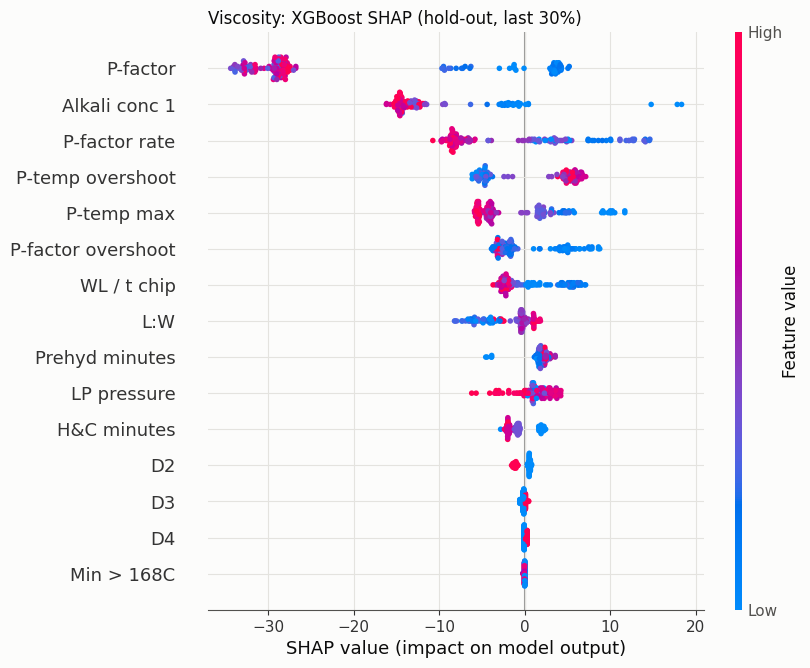

In [43]:
plots.shap_summary(df, feats);

### Partial dependence + plain binned means
PDP = model view; the quintile table = raw data view. They should tell the same story.

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\pdp_top.png
P-factor


,mean,count
pfactor_actual_last_prehydrolysis,,
"(280.252, 319.828]",783.8,97
"(319.828, 333.635]",776.1,97
"(333.635, 344.557]",793.2,96
"(344.557, 364.704]",784.8,97
"(364.704, 509.527]",745.4,97


Alkali conc 1


,mean,count
alkali_accumulator1_conc_mean_hot_liquor_filling,,
"(34.853, 36.045]",807.3,97
"(36.045, 36.517]",784.1,97
"(36.517, 36.997]",772.8,97
"(36.997, 37.271]",772.5,96
"(37.271, 38.142]",746.4,97


P-factor rate


,mean,count
pfactor_rate,,
"(0.874, 3.96]",794.1,97
"(3.96, 4.201]",795.4,97
"(4.201, 4.528]",785.7,96
"(4.528, 4.964]",758.4,97
"(4.964, 6.066]",749.6,97


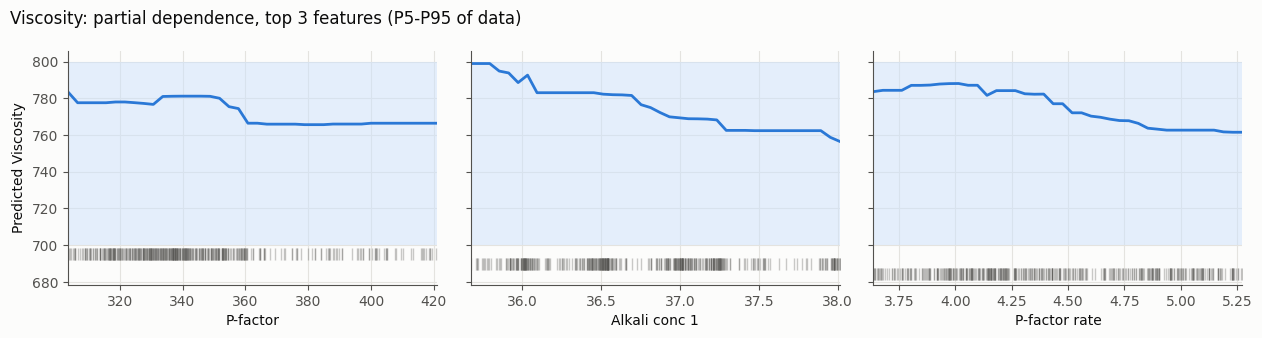

In [44]:
plots.pdp_top(df, feats, effects);
for f in [x for x in effects.index if not x.startswith("is_D")][:config.TOP_N_PDP]:
    print(data.label(f))
    display(explain.binned_means(df, f))

## 4. Actual vs predicted over time

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\pred_vs_actual_xgboost.png


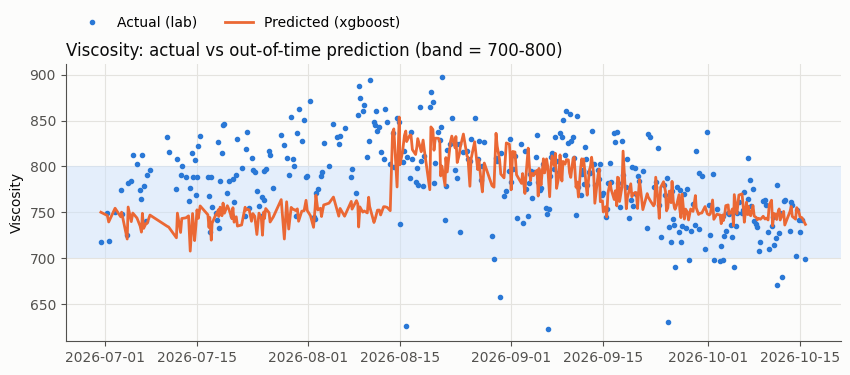

In [45]:
plots.predicted_vs_actual(df, models.time_split_predict(df, feats, "xgboost"), "xgboost");

## Reading the result
- Below the gate -> **do not optimize** on this model; use the feature table as hypotheses only.
- Trust a driver when several columns agree (sign + rank) and the binned means show the same shape.
- Log each run in `update.md` (What was done / Results / Found by).